In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("图片处理工具已准备好！")
print("OpenCV版本：", cv2.__version__)

图片处理工具已准备好！
OpenCV版本： 5.0.0


图片下载并读取成功！
图片尺寸（高度，宽度）： (1000, 2000)


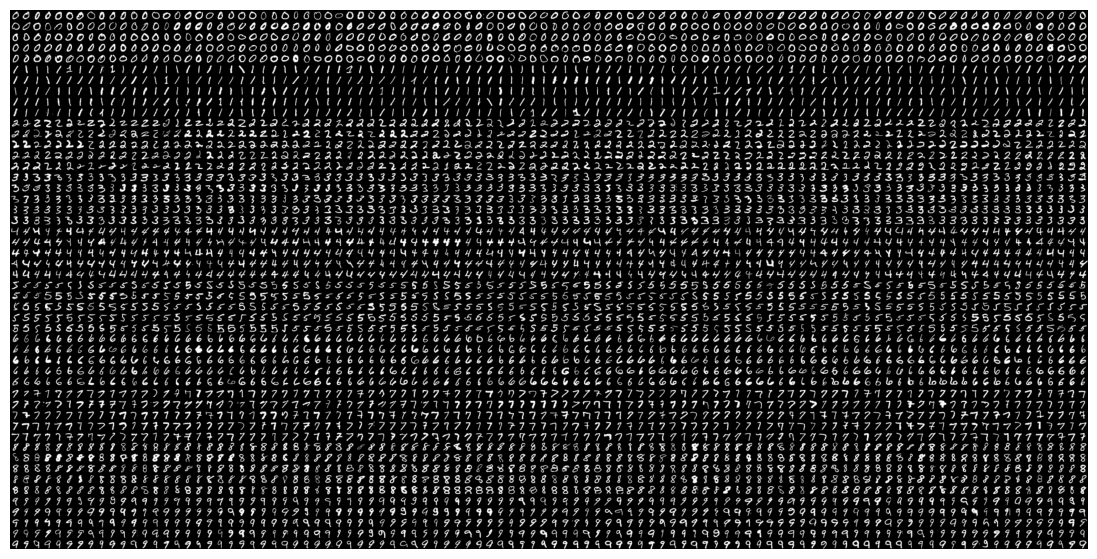

In [5]:
# 准备下载文件的工具
import urllib.request

# 官方示例图片的下载地址
url = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/digits.png"

# 下载图片，保存为 digits.png
urllib.request.urlretrieve(url, "digits.png")

# 读取图片，以灰度形式保存到 img 中
img = cv2.imread("digits.png", cv2.IMREAD_GRAYSCALE)

# 检查图片是否读取成功
if img is None:
    raise ValueError("图片读取失败，请把报错发给我。")

print("图片下载并读取成功！")
print("图片尺寸（高度，宽度）：", img.shape)

# 显示图片
plt.figure(figsize=(14, 7))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

切分成功！
数字图片数量： 5000
每张小图的尺寸： (20, 20)


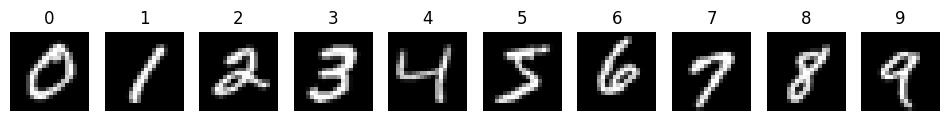

In [6]:
# 把大图先切成50行，再把每行切成100个小方格
cells = [np.hsplit(row, 100) for row in np.vsplit(img, 50)]

# 把这些小方格整理为5000张20×20像素的数字图片
digits = np.array(cells).reshape(5000, 20, 20)

print("切分成功！")
print("数字图片数量：", len(digits))
print("每张小图的尺寸：", digits[0].shape)

# 从0到9，每种数字各展示一张
plt.figure(figsize=(12, 2))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(digits[i * 500], cmap="gray")
    plt.title(str(i))
    plt.axis("off")

plt.show()

In [7]:
# 建立正确答案：500个0、500个1，一直到500个9
labels = np.repeat(np.arange(10), 500).astype(np.int32)

print("标签创建成功！")
print("图片总数：", len(digits))
print("标签总数：", len(labels))

# 检查每个数字对应多少张图片
for number in range(10):
    count = np.sum(labels == number)
    print("数字", number, "对应", count, "张图片")

标签创建成功！
图片总数： 5000
标签总数： 5000
数字 0 对应 500 张图片
数字 1 对应 500 张图片
数字 2 对应 500 张图片
数字 3 对应 500 张图片
数字 4 对应 500 张图片
数字 5 对应 500 张图片
数字 6 对应 500 张图片
数字 7 对应 500 张图片
数字 8 对应 500 张图片
数字 9 对应 500 张图片


In [9]:
# 把图片和答案恢复成原来的50行、100列排列
image_grid = digits.reshape(50, 100, 20, 20)
label_grid = labels.reshape(50, 100)

# 每一行的左半部分用于训练
train_images = image_grid[:, :50].reshape(-1, 20, 20)
train_labels = label_grid[:, :50].reshape(-1)

# 每一行的右半部分用于测试
test_images = image_grid[:, 50:].reshape(-1, 20, 20)
test_labels = label_grid[:, 50:].reshape(-1)

print("数据划分完成！")
print("训练图片数量：", len(train_images))
print("训练答案数量：", len(train_labels))
print("测试图片数量：", len(test_images))
print("测试答案数量：", len(test_labels))

# 检查每种数字在两份数据中的数量
for number in range(10):
    train_count = np.sum(train_labels == number)
    test_count = np.sum(test_labels == number)
    print("数字", number, "：训练", train_count, "张，测试", test_count, "张")


数据划分完成！
训练图片数量： 2500
训练答案数量： 2500
测试图片数量： 2500
测试答案数量： 2500
数字 0 ：训练 250 张，测试 250 张
数字 1 ：训练 250 张，测试 250 张
数字 2 ：训练 250 张，测试 250 张
数字 3 ：训练 250 张，测试 250 张
数字 4 ：训练 250 张，测试 250 张
数字 5 ：训练 250 张，测试 250 张
数字 6 ：训练 250 张，测试 250 张
数字 7 ：训练 250 张，测试 250 张
数字 8 ：训练 250 张，测试 250 张
数字 9 ：训练 250 张，测试 250 张


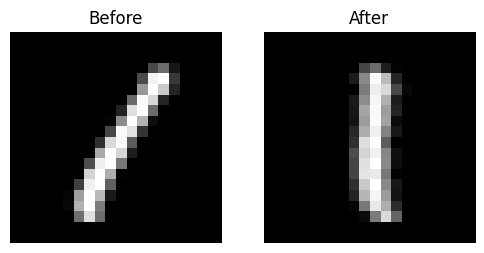

倾斜校正方法已准备好！


In [11]:
# 定义一个“减轻数字倾斜”的处理方法
def deskew(image):
    moments = cv2.moments(image)

    # 如果无法可靠计算倾斜程度，就保留原图
    if abs(moments["mu02"]) < 0.01:
        return image.copy()

    # 根据笔画分布估计倾斜程度
    skew = moments["mu11"] / moments["mu02"]

    # 设置校正方式
    matrix = np.float32([
        [1, skew, -10 * skew],
        [0, 1, 0]
    ])

    # 执行校正，图片仍保持20×20像素
    corrected = cv2.warpAffine(
        image,
        matrix,
        (20, 20),
        flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR
    )

    return corrected


# 取出一张数字1的图片，观察校正效果
sample = train_images[250]
corrected_sample = deskew(sample)

# 左边显示原图
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(sample, cmap="gray")
plt.title("Before")
plt.axis("off")

# 右边显示校正后的图片
plt.subplot(1, 2, 2)
plt.imshow(corrected_sample, cmap="gray")
plt.title("After")
plt.axis("off")

plt.show()
print("倾斜校正方法已准备好！")

In [12]:
# 定义HOG特征提取方法
def hog(image):
    # 计算图片在水平和垂直方向上的亮暗变化
    gx = cv2.Sobel(image, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(image, cv2.CV_32F, 0, 1)

    # 得到变化的强度和方向
    magnitude, angle = cv2.cartToPolar(gx, gy)

    # 把方向分成16类
    bins = (angle * 16 / (2 * np.pi)).astype(np.int32) % 16

    features = []

    # 把20×20的图片分成4块，每块10×10
    for y in (0, 10):
        for x in (0, 10):
            block_bins = bins[y:y + 10, x:x + 10]
            block_magnitude = magnitude[y:y + 10, x:x + 10]

            # 统计这一块中各方向的强度
            histogram = np.bincount(
                block_bins.ravel(),
                weights=block_magnitude.ravel(),
                minlength=16
            )

            features.extend(histogram)

    return np.array(features, dtype=np.float32)


# 对训练图片逐张进行：倾斜校正 → HOG特征提取
train_features = np.array(
    [hog(deskew(image)) for image in train_images],
    dtype=np.float32
)

# 对测试图片采用完全相同的处理
test_features = np.array(
    [hog(deskew(image)) for image in test_images],
    dtype=np.float32
)

print("HOG特征提取完成！")
print("训练特征的尺寸：", train_features.shape)
print("测试特征的尺寸：", test_features.shape)


HOG特征提取完成！
训练特征的尺寸： (2500, 64)
测试特征的尺寸： (2500, 64)


In [18]:
# 准备SVM工具；已经安装的话，会直接使用
%pip -q install scikit-learn

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 整理训练图片的特征和正确答案
training_data = np.asarray(train_features, dtype=np.float64)
training_answers = np.asarray(train_labels, dtype=np.int32).ravel()

# 创建模型：
# 先统一特征的数值尺度，再交给线性SVM学习
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=2.67)
)

print("正在训练SVM，请稍等……")

# 只使用训练集进行学习
svm.fit(training_data, training_answers)

print("SVM训练完成！")
print("训练图片数量：", training_data.shape[0])
print("每张图片的特征数量：", training_data.shape[1])
print("模型学到的类别：", svm.classes_)

正在训练SVM，请稍等……
SVM训练完成！
训练图片数量： 2500
每张图片的特征数量： 64
模型学到的类别： [0 1 2 3 4 5 6 7 8 9]


In [19]:
# 整理测试图片的特征
testing_data = np.asarray(test_features, dtype=np.float64)

# 让训练好的模型预测，只提供图片特征
predictions = svm.predict(testing_data)

# 预测完成后，再取出正确答案评分
testing_answers = np.asarray(test_labels).ravel()

# 统计答对、答错的数量
total = len(testing_answers)
correct = int(np.sum(predictions == testing_answers))
wrong = total - correct

# 计算准确率
accuracy = correct / total * 100

print("测试完成！")
print("测试图片总数：", total)
print("识别正确数量：", correct)
print("识别错误数量：", wrong)
print(f"识别准确率：{accuracy:.2f}%")

测试完成！
测试图片总数： 2500
识别正确数量： 2347
识别错误数量： 153
识别准确率：93.88%
